# Boundary effect (group size 16)

How much do speed, polarization, nearest-neighbour distance (NND) and subgroup centroid distance depend on data recorded close to the arena wall?
Each panel overlays two density histograms, **all data** and **outer 25 % of the arena area removed**, with their Hellinger distance $H$ above the panel (0 = identical, 1 = no overlap).

* The wall of each trial = its outermost tracked point (radius $R$); removing the outer 25 % of the area keeps everything within $R\sqrt{0.75} = 0.866\,R$.
* Speed and NND (one value per fish per frame) use the fish's distance from the centre; polarization and centroid distance (one value per frame) use the group centroid's distance.
* Frames need at least 75 % of the fish tracked (NND, polarization, centroid distance); files with < 1 % tracked positions are skipped.

Two figures are saved in `../Results` (PNG and PDF, 300 dpi):
1. `boundary_effect_single_species_gs16`: columns a-f = TB, RB, BPT, ST, NT, RET; rows i-iii = speed, polarization, NND.
2. `boundary_effect_mixed_species_gs16`: columns a-d = TB (A) - RB (B), BPT (A) - ST (B), NT (A) - ST (B), NT (A) - RET (B); rows i-iv = speed, polarization, NND, centroid distance.

## 1. Settings

In [1]:
%matplotlib inline
import glob, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.lines import Line2D

DATA, OUT = os.path.join("..", "Data"), os.path.join("..", "Results")
PAIRS = [("TB", "RB"), ("BPT", "ST"), ("NT", "ST"), ("NT", "RET")]     # (species A, species B); A = first 8 fish of a mixed npz
SINGLE = ["TB", "RB", "BPT", "ST", "NT", "RET"]                        # column order of the single-species figure
MIN_VALID, MIN_FILE = 0.75, 0.01        # frames need >= 75 % of fish tracked; skip files with < 1 % of positions tracked
LEVELS = [(0.0, "All data", "#E69F00"), (0.25, "Outer 25 % of area removed", "#0072B2")]   # (area fraction removed, label, colour)
EDGES = {"speed": np.arange(0, 100 + 1e-9, 0.1), "nnd": np.arange(0, 60 + 1e-9, 0.05),     # fine bins; merged for plotting (ROWS)
         "pol": np.arange(0, 1 + 1e-9, 0.0025), "cd": np.arange(0, 60 + 1e-9, 0.05)}

## 2. Functions

In [2]:
def nnd(pos, chunk=2000):
    """pos (frames, fish, 2) -> (frames, fish) distance to the nearest other fish (NaN if untracked)."""
    out = np.full(pos.shape[:2], np.nan, np.float32)
    for s in range(0, len(pos), chunk):
        D = np.linalg.norm(pos[s:s + chunk, :, None] - pos[s:s + chunk, None], axis=3)
        D[np.isnan(D)] = np.inf
        D[:, np.eye(pos.shape[1], dtype=bool)] = np.inf
        m = D.min(axis=2)
        out[s:s + chunk] = np.where(np.isfinite(m), m, np.nan)
    return out


def polarization(vel):
    """Length of the mean unit heading per frame; NaN if fewer than MIN_VALID of the fish have a heading."""
    speed = np.linalg.norm(vel, axis=2)
    ok = np.isfinite(speed) & (speed > 1e-9)
    u = np.where(ok[..., None], vel / np.where(ok, speed, 1.0)[..., None], 0.0)
    P = np.linalg.norm(u.sum(axis=1), axis=1) / np.maximum(ok.sum(1), 1)
    P[ok.sum(1) < max(2, np.ceil(MIN_VALID * vel.shape[1]))] = np.nan
    return P


COUNTS = {}                              # COUNTS[metric, group, fraction removed] = histogram counts on EDGES[metric]

def add(metric, group, x, r, wall):
    """Histogram the values x for every level of LEVELS, keeping values whose distance r from the centre is inside the cut."""
    for f, _, _ in LEVELS:
        keep = r <= (wall * np.sqrt(1 - f) if f else np.inf)
        c = np.histogram(np.clip(x[keep], 0, EDGES[metric][-1] - 1e-9), EDGES[metric])[0]
        COUNTS[metric, group, f] = COUNTS.get((metric, group, f), 0) + c


def process_trial(pos, vel, group, is_a=None):
    """One trial: speed and NND per fish (fish distance from the centre), polarization and centroid distance per frame (centroid distance)."""
    tracked = np.isfinite(pos).all(axis=2)
    if tracked.mean() < MIN_FILE:
        return print("skipped a file of", group)
    n = tracked.sum(1)
    frame_ok = n >= np.ceil(MIN_VALID * pos.shape[1])
    r_fish = np.where(tracked, np.hypot(pos[..., 0], pos[..., 1]), np.nan)
    wall = np.nanmax(r_fish)                                              # outermost tracked point = wall
    p0 = np.where(tracked[..., None], pos, 0.0)
    r_frame = np.linalg.norm(p0.sum(1) / np.maximum(n, 1)[:, None], axis=1)
    speed = np.linalg.norm(vel, axis=2); ok = tracked & np.isfinite(speed)
    add("speed", group, speed[ok], r_fish[ok], wall)
    d = nnd(pos); ok = np.isfinite(d) & frame_ok[:, None]
    add("nnd", group, d[ok], r_fish[ok], wall)
    P = polarization(vel); ok = np.isfinite(P) & frame_ok
    add("pol", group, P[ok], r_frame[ok], wall)
    if is_a is not None:                                                  # distance between the centroids of the two species
        wA, wB = tracked & is_a, tracked & ~is_a
        ok = (wA.sum(1) >= np.ceil(MIN_VALID * is_a.sum(1))) & (wB.sum(1) >= np.ceil(MIN_VALID * (~is_a).sum(1)))
        cA = (p0 * wA[..., None]).sum(1) / np.maximum(wA.sum(1), 1)[:, None]
        cB = (p0 * wB[..., None]).sum(1) / np.maximum(wB.sum(1), 1)[:, None]
        add("cd", group, np.linalg.norm(cA - cB, axis=1)[ok], r_frame[ok], wall)

## 3. Load all trials

In [3]:
for sp in SINGLE:                                                           # single-species trials
    for f in sorted(glob.glob(os.path.join(DATA, f"{sp}16_*_traj_bl.npz"))):
        z = np.load(f)
        process_trial(z["positions"].astype(float), z["velocities"], f"{sp}16")
for a, b in PAIRS:                                                          # mixed trials
    if (a, b) == ("TB", "RB"):                                              # TB8+RB8 come from the csv (species in "SPECIES ID")
        for _, d in pd.read_csv(os.path.join(DATA, "TBRB16_traj_bl.csv")).groupby("Replicate", sort=False):
            T = len(d) // 16
            process_trial(d[["x", "y"]].to_numpy(float)[:T * 16].reshape(T, 16, 2), d[["vx", "vy"]].to_numpy(float)[:T * 16].reshape(T, 16, 2),
                          f"{a}8{b}8", d["SPECIES ID"].to_numpy()[:T * 16].reshape(T, 16) == a)
    else:
        for f in sorted(glob.glob(os.path.join(DATA, f"{a}8{b}8_*_traj_bl.npz")) + glob.glob(os.path.join(DATA, f"{b}8{a}8_*_traj_bl.npz"))):
            z = np.load(f)
            pos = z["positions"].astype(float)
            process_trial(pos, z["velocities"], f"{a}8{b}8", np.tile(np.arange(pos.shape[1]) < 8, (len(pos), 1)))
print("done")

skipped a file of BPT16


skipped a file of ST16


done


## 4. Figures
`ROWS`: x label, x range (None = 0 to the 99.5th percentile of the panel), number of fine bins merged per bar, x ticks.
The mixed-species figure uses the same x ranges as the mixed-species group-property figures (`MIXED_XLIMS`). Each panel's y axis goes up to its own tallest bar.
Each panel shows the Hellinger distance between the two distributions (same bins as plotted), $H = \sqrt{1 - \sum_k \sqrt{p_k q_k}\,\Delta x}$: 0 = identical, 1 = no overlap.

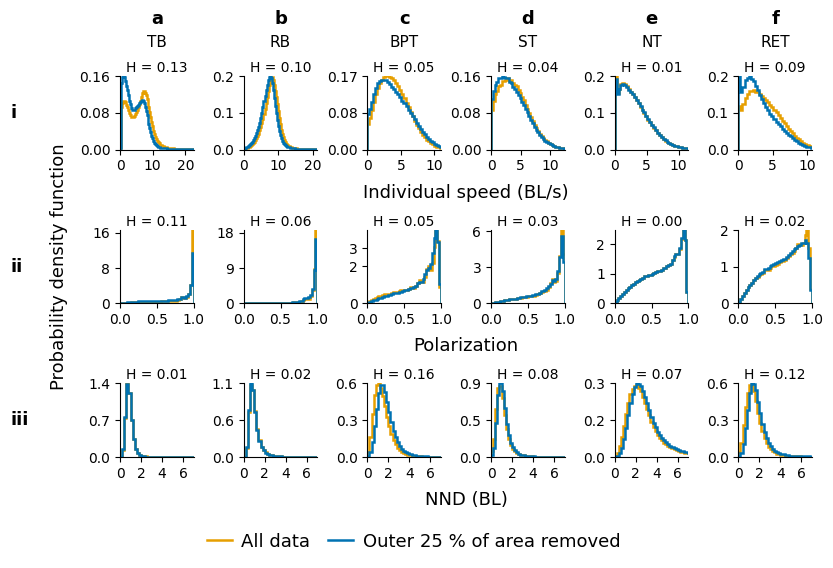

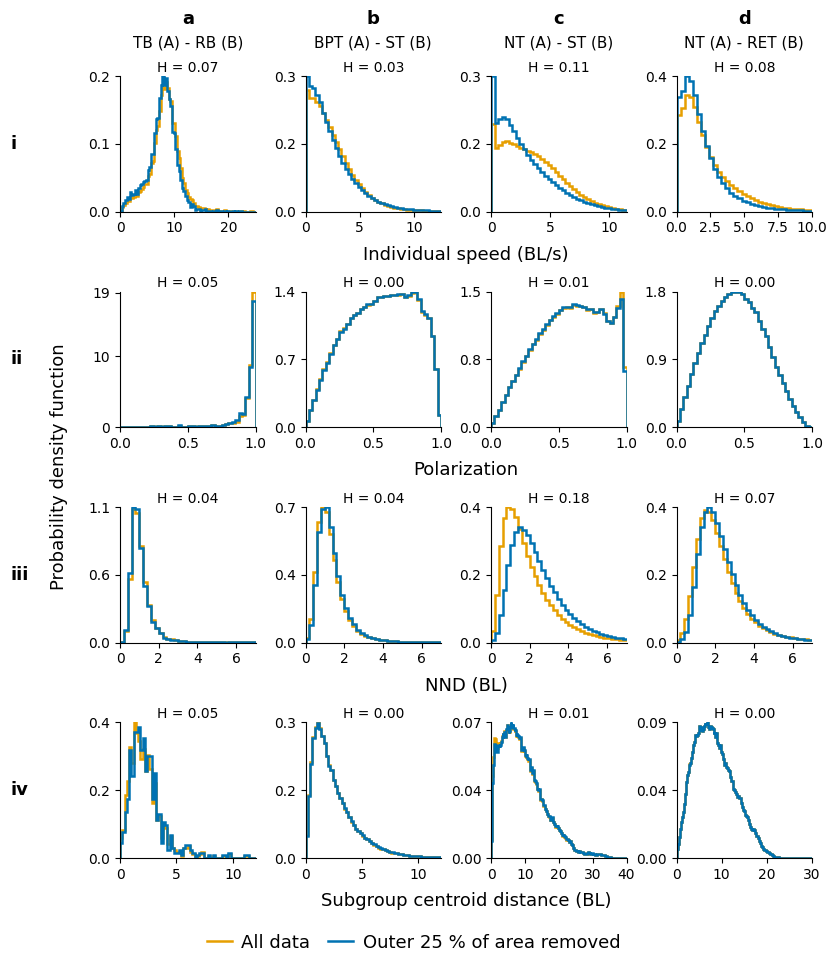

In [4]:
WIDTH, LABEL_FONT, TICK_FONT, lw = 8.27, 13, 10, 1.8       # A4 width (in), font sizes (pt), line width
L, R, T, B, WGAP, HGAP = 1.2, 0.15, 0.97, 1.05, 0.50, 0.80   # margins and gaps between panels (in)
ROWS = {"speed": ("Individual speed (BL/s)", None, 3, None),       # 0.3 BL/s bars
        "pol": ("Polarization", (0, 1), 10, [0, 0.5, 1]),            # 0.025 bars
        "nnd": ("NND (BL)", (0, 7), 4, None),                        # 0.2 BL bars
        "cd": ("Subgroup centroid distance (BL)", None, 4, None)}    # 0.2 BL bars
MIXED_XLIMS = {"speed": [(0, 25), (0, 12.5), (0, 11.5), (0, 10)], "pol": (0, 1), "nnd": (0, 7), "cd": [(0, 12), (0, 12), (0, 40), (0, 30)]}


def set_y_to_max(ax, ymax):
    """y axis from 0 to the tallest bar, ticks at 0, middle and top."""
    ax.set_ylim(0, ymax)
    yt = sorted({0, int(round(ymax / 2)), int(ymax)}) if ymax >= 2 else [0, ymax / 2, ymax]
    ax.set_yticks(yt)
    ax.set_yticklabels([str(t) if ymax >= 2 else f"{t:.{1 if ymax >= 0.2 else 2}f}" for t in yt])


def boundary_figure(groups, titles, metrics, out_name, xlims=None):
    """One column per group, one row per metric; each panel overlays the levels of LEVELS."""
    nr, nc = len(metrics), len(groups)
    P = (WIDTH - L - R - (nc - 1) * WGAP) / nc                            # square panels fill the width
    H = T + B + nr * P + (nr - 1) * HGAP
    fig = plt.figure(figsize=(WIDTH, H))
    gs = GridSpec(nr, nc, figure=fig, wspace=WGAP / P, hspace=HGAP / P, left=L / WIDTH, right=1 - R / WIDTH, bottom=B / H, top=1 - T / H)
    axes = np.array([[fig.add_subplot(gs[i, j]) for j in range(nc)] for i in range(nr)])
    for i, m in enumerate(metrics):
        xlabel, xl, merge, xticks = ROWS[m]
        xl = (xlims or {}).get(m, xl)
        for j, g in enumerate(groups):
            ax, hmax, dens_ = axes[i, j], 0, []
            for f, label, col in LEVELS:
                cnt = COUNTS[m, g, f]
                k = len(cnt) // merge * merge
                c, e = cnt[:k].reshape(-1, merge).sum(1), EDGES[m][:k + 1:merge]          # merge fine bins
                dens = c / (c.sum() * np.diff(e))
                ax.stairs(dens, e, color=col, lw=lw); hmax = max(hmax, dens.max()); dens_.append(dens)
            H_ = np.sqrt(max(0.0, 1 - np.sum(np.sqrt(dens_[0] * dens_[1]) * np.diff(e))))   # Hellinger distance, all data vs 25 % removed
            allc = COUNTS[m, g, 0.0]
            q995 = EDGES[m][1:][np.searchsorted(np.cumsum(allc) / allc.sum(), 0.995)]       # 99.5th percentile of all data
            x_ = xl[j] if isinstance(xl, list) else xl
            ax.set_xlim(*(x_ or (0, q995)))
            ax.set_xticks(xticks) if xticks else ax.locator_params(axis="x", nbins=4)
            set_y_to_max(ax, hmax)
            ax.set_title(f"H = {H_:.2f}", fontsize=TICK_FONT, pad=3)            # Hellinger distance above the panel
            ax.spines[["top", "right"]].set_visible(False); ax.tick_params(labelsize=TICK_FONT)
        p0, p1 = axes[i, 0].get_position(), axes[i, -1].get_position()
        fig.text((p0.x0 + p1.x1) / 2, p0.y0 - 0.34 / H, xlabel, ha="center", va="top", fontsize=LABEL_FONT)       # x label per row
        fig.text(0.1 / WIDTH, (p0.y0 + p0.y1) / 2, ["i", "ii", "iii", "iv"][i], ha="left", va="center", fontsize=LABEL_FONT, weight="bold")
    for j, ax in enumerate(axes[0]):                                      # column title and letter above the top row
        bb = ax.get_position()
        fig.text((bb.x0 + bb.x1) / 2, bb.y1 + 0.26 / H, titles[j], ha="center", va="bottom", fontsize=11)
        fig.text((bb.x0 + bb.x1) / 2, bb.y1 + (0.29 + 1.25 * 11 / 72) / H, "abcdef"[j], ha="center", va="bottom", fontsize=LABEL_FONT, weight="bold")
    top, bot = axes[0, 0].get_position().y1, axes[-1, 0].get_position().y0
    fig.text(0.5 / WIDTH, (top + bot) / 2, "Probability density function", rotation=90, ha="left", va="center", fontsize=LABEL_FONT)
    fig.legend(handles=[Line2D([], [], color=col, lw=lw, label=lab) for _, lab, col in LEVELS], loc="lower center", ncol=2, frameon=False,
               fontsize=LABEL_FONT, handlelength=1.4, handletextpad=0.5, columnspacing=1.0, borderaxespad=0, bbox_to_anchor=(0.5, 0.04 / H))
    for ext in ("png", "pdf"):
        fig.savefig(os.path.join(OUT, f"{out_name}.{ext}"), dpi=300)
    plt.show()


boundary_figure([f"{sp}16" for sp in SINGLE], SINGLE, ["speed", "pol", "nnd"], "boundary_effect_single_species_gs16")
boundary_figure([f"{a}8{b}8" for a, b in PAIRS], [f"{a} (A) - {b} (B)" for a, b in PAIRS], ["speed", "pol", "nnd", "cd"],
                "boundary_effect_mixed_species_gs16", MIXED_XLIMS)